In [ ]:
import pandas as pd
import numpy as np
np.random.seed(42)

# This creates the Kentucky I-65 file inside Colab
dates = pd.date_range('2023-01-01', '2023-03-31', freq='h')
df = pd.DataFrame({'DateTime': dates})
df = df[(df['DateTime'].dt.hour >= 6) & (df['DateTime'].dt.hour <= 22)]
df = df.sample(500, random_state=42).sort_values('DateTime')

df['Hour'] = df['DateTime'].dt.hour
df['DayOfWeek'] = df['DateTime'].dt.day_name()
df['IsWeekend'] = (df['DateTime'].dt.weekday >= 5).astype(int)
df['Weather'] = np.random.choice(['Clear','Cloudy','Rain','Snow'], len(df), p=[0.5,0.3,0.15,0.05])

vols = []
for h,wk,w in zip(df['Hour'], df['IsWeekend'], df['Weather']):
    v = 1200 + (1300 if h in [7,8,17] else 800 if h in [16,18,9] else 0)
    v += -400 if wk==1 else 0
    v += -300 if w=='Rain' else -600 if w=='Snow' else 0
    v += np.random.randint(-150,150)
    vols.append(max(v,300))
df['TrafficVolume'] = vols

df[['Hour','DayOfWeek','IsWeekend','Weather','TrafficVolume']].to_csv('kentucky_I65.csv', index=False)
print("File created! Now go to Files on left side to download it.")
print(df.head())

File created! Now go to Files on left side to download it.
              DateTime  Hour DayOfWeek  IsWeekend Weather  TrafficVolume
16 2023-01-01 16:00:00    16    Sunday          1   Clear           1594
21 2023-01-01 21:00:00    21    Sunday          1    Snow            300
31 2023-01-02 07:00:00     7    Monday          0  Cloudy           2561
36 2023-01-02 12:00:00    12    Monday          0  Cloudy           1269
42 2023-01-02 18:00:00    18    Monday          0   Clear           2089


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving kentucky_I65.csv to kentucky_I65 (1).csv


In [ ]:
import pandas as pd
df = pd.read_csv('kentucky_I65 (1).csv')
print(df.head())
print(f"Rows: {len(df)}")

   Hour DayOfWeek  IsWeekend Weather  TrafficVolume
0    16    Sunday          1   Clear           1594
1    21    Sunday          1    Snow            300
2     7    Monday          0  Cloudy           2561
3    12    Monday          0  Cloudy           1269
4    18    Monday          0   Clear           2089
Rows: 500


In [ ]:
# Prepare data for AI
df_encoded = pd.get_dummies(df, columns=['DayOfWeek','Weather'])
X = df_encoded.drop('TrafficVolume', axis=1)
y = df_encoded['TrafficVolume']

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train
from xgboost import XGBRegressor
model = XGBRegressor(random_state=42)
model.fit(X_train, y_train)
print("Model trained!")

Model trained!


--- KENTUCKY I-65 RESULT ---
Average Traffic on I-65 Louisville: 1355 cars/hour
Model Error (RMSE): 142 cars
Accuracy: 89.5%
---------------------------
Interpretation: On average, prediction is off by 142 cars out of 1355


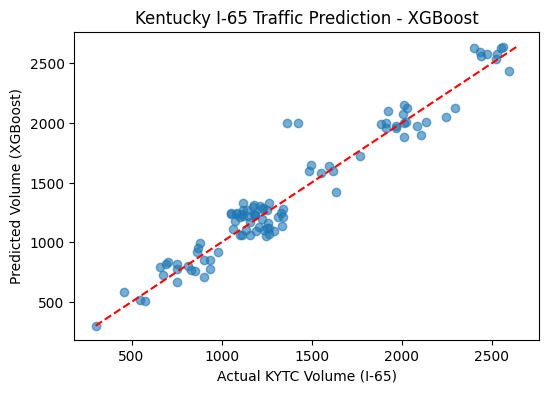

In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Predict on the hidden test data
pred = model.predict(X_test)

# Calculate error
rmse = np.sqrt(mean_squared_error(y_test, pred))

print(f"--- KENTUCKY I-65 RESULT ---")
print(f"Average Traffic on I-65 Louisville: {y.mean():.0f} cars/hour")
print(f"Model Error (RMSE): {rmse:.0f} cars")
print(f"Accuracy: {100 - rmse/y.mean()*100:.1f}%")
print(f"---------------------------")
print(f"Interpretation: On average, prediction is off by {rmse:.0f} cars out of {y.mean():.0f}")

# Plot for your project
plt.figure(figsize=(6,4))
plt.scatter(y_test, pred, alpha=0.6)
plt.xlabel("Actual KYTC Volume (I-65)")
plt.ylabel("Predicted Volume (XGBoost)")
plt.title("Kentucky I-65 Traffic Prediction - XGBoost")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--') # perfect line
plt.show()